# 08 · Evaluación final y diseño del experimento en planta

**Proyecto:** Análisis experimental MC4–Skinpass · Ternium Pesquería · producción 2025
**Fase:** 6 (selección y protocolo de la intervención)

## A. Contexto de la etapa

**¿Qué hacemos?** Cerramos la Fase 1 y abrimos la Fase 2 de la propuesta:
1. **Evaluación final:** usamos por primera vez el periodo reservado (noviembre-diciembre de 2025) para comprobar si los hallazgos principales se sostienen en datos que ningún análisis tocó.
2. **Tabla de decisión:** comparamos las seis intervenciones candidatas por impacto, evidencia, riesgo y facilidad de prueba.
3. **Protocolo** del experimento principal y de un segundo experimento técnico, con análisis de potencia.

**La pregunta que guía todo el proyecto:** *¿qué podemos aprender de los datos que nos permita decidir qué cambiar en la operación real?* Este notebook es la respuesta operativa.

## B. Fundamento conceptual

**1. Muestra reservada (hold-out) y criterios de refutación.** Un hallazgo se vuelve más creíble si se sostiene en datos que no se usaron para encontrarlo. Para que la prueba sea honesta, el criterio de "se sostiene / se refuta" se escribe **antes** de mirar el resultado (sección 1). *Transparencia:* al preparar el protocolo de la intervención A se consultó la tasa de retención por peso en noviembre-diciembre; las demás comprobaciones se corren aquí por primera vez.

**2. Diferencias en diferencias (DiD).** Compara el cambio antes/después en un grupo tratado contra el cambio en un grupo de control. Lo que cambie en ambos (temporada, mezcla de productos, demanda) se cancela. El supuesto clave: sin intervención, ambos grupos habrían seguido **tendencias paralelas**.

**3. Aleatorización por conglomerados.** La regla de la intervención A se aplica en la planeación, por familia de producto (PRAM), no pieza por pieza. Por eso la **unidad experimental es el PRAM**: se sortea qué PRAM reciben la regla. Las piezas de un mismo PRAM no son independientes; la potencia depende del número de PRAM, no del de piezas.

**4. Análisis de potencia por simulación.** La potencia es la probabilidad de detectar el efecto si existe. La estimamos **simulando el experimento sobre los datos históricos**: tomamos semanas reales, sorteamos PRAM a tratamiento, aplicamos un efecto supuesto y vemos con qué frecuencia la prueba lo detecta. Se usa la variabilidad real de la planta, no fórmulas idealizadas.

**5. Guardrails y reglas de paro.** Son métricas que **no deben empeorar** aunque la métrica principal mejore (por ejemplo, la retención por peso bajo si se dividen más rollos). Si cruzan un límite fijado de antemano, el experimento se detiene.

**6. Operación evolutiva (Box, 1957).** Es lo que pide la guía del curso: experimentar en producción con cambios pequeños, seguros y sistemáticos, en bloques (programa, turno, día), sin detener la operación.

## C. Objetivo y metodología

| # | Paso | Resultado |
|---|---|---|
| 1 | Criterios de refutación, escritos antes de evaluar | Tabla de criterios |
| 2 | Evaluación en noviembre-diciembre | ¿Se sostiene cada hallazgo? |
| 3 | Tabla de decisión de las seis intervenciones | Intervención principal y secundaria |
| 4 | Protocolo de la intervención A + potencia por simulación | Diseño, duración, criterios de éxito, guardrails |
| 5 | Protocolo del experimento técnico (corrección del preset al inicio de campaña) + potencia | Número de campañas necesario |
| 6 | Datos que faltan en el Skinpass | Lista de instrumentación |

## D. Implementación
### 0. Configuración

In [1]:
# Solo en Colab: descarga el repo (datos incluidos) e instala dependencias. En local no hace nada.
import os, sys, subprocess
if 'google.colab' in sys.modules:
    REPO = '/content/Entregable_Reto'
    if os.path.exists(REPO):
        # La copia de Colab es desechable: se iguala a GitHub aunque tenga figuras o archivos regenerados.
        subprocess.run(['git', '-C', REPO, 'fetch', '-q', 'origin', 'main'], check=True)
        subprocess.run(['git', '-C', REPO, 'reset', '-q', '--hard', 'origin/main'], check=True)
    else:
        subprocess.run(['git', 'clone', '-q', 'https://github.com/DiegoLarrieta/Entregable_Reto.git', REPO], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', f'{REPO}/requirements.txt'], check=True)
    os.chdir(f'{REPO}/notebooks')

In [2]:
import sys, warnings
from pathlib import Path
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'ternium.py').exists())
sys.path.append(str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from scipy import stats
from src.ternium import *

warnings.filterwarnings('ignore')
estilo()
pd.set_option('display.max_columns', 30, 'display.width', 170)
RESULTADOS = RAIZ / 'resultados'; RESULTADOS.mkdir(exist_ok=True)
SEMILLA = 2025
rng = np.random.default_rng(SEMILLA)

B = cargar_base_analitica()
B['prod_ancho'] = B['producto'] + ' | ' + B['rango_ancho']
B['grupo_peso'] = np.select([(B.excede_peso_orden == 1) & (B.dividido == 0), (B.excede_peso_orden == 1) & (B.dividido == 1)],
                            ['Excede y NO se divide', 'Excede y se divide'], 'Cabe en la orden')
ENT, PRU = B[~B['en_prueba']].copy(), B[B['en_prueba']].copy()
print(f"Entrenamiento: {len(ENT):,} piezas · prueba (nov-dic): {len(PRU):,} piezas")

Entrenamiento: 47,461 piezas · prueba (nov-dic): 9,638 piezas


### 1. Criterios de refutación (fijados antes de evaluar)

| # | Hallazgo (notebook) | Se **sostiene** si en noviembre-diciembre… | Se **refuta** si… |
|---|---|---|---|
| H1 | Peso: los rollos que exceden la orden y no se dividen se retienen por PESO (+) (05) | su tasa es ≥ 20 % y al menos 10 veces la del resto | tasa < 20 % o razón < 10 |
| H2 | El MC4 no mejora la predicción de ΔBending dentro de producto (04) | agregar el MC4 a los controles mejora el R² dentro de producto en < 2 puntos | mejora ≥ 2 puntos |
| H3 | El Skinpass (con operador) sí mejora la predicción de ΔBending (04) | mejora ≥ 2 puntos sobre los controles | mejora < 2 puntos |
| H4 | Asentamiento del rodillo: ΔFuerza menor en las piezas 1-10 de cada campaña (07) | coeficiente negativo con IC 95 % que excluye 0 | IC incluye 0 o signo positivo |
| H5 | Días de espera → más ΔFuerza (06) | pendiente positiva con IC 95 % que excluye 0 | IC incluye 0 o signo negativo |

### 2. Evaluación en el periodo reservado
#### H1 · Retención por PESO (+) según el peso frente a la orden

In [3]:
def tabla_peso(df):
    t = df.groupby('grupo_peso').agg(piezas=('ret_peso_mas', 'size'), peso_mas_pct=('ret_peso_mas', 'mean'), peso_menos_pct=('ret_peso_menos', 'mean'))
    t[['peso_mas_pct', 'peso_menos_pct']] *= 100
    return t
h1 = pd.concat({'entrenamiento': tabla_peso(ENT), 'prueba': tabla_peso(PRU), 'prueba sin frontera': tabla_peso(PRU[~PRU.frontera])}, axis=1)
tasa_nd = PRU.loc[PRU.grupo_peso == 'Excede y NO se divide', 'ret_peso_mas'].mean()
tasa_resto = PRU.loc[PRU.grupo_peso != 'Excede y NO se divide', 'ret_peso_mas'].mean()
H1 = tasa_nd >= .20 and tasa_nd / max(tasa_resto, 1e-9) >= 10
print(f"Prueba: tasa en 'excede y no divide' = {100 * tasa_nd:.1f} % · resto = {100 * tasa_resto:.2f} % · razón = {tasa_nd / tasa_resto:.0f}× → {'SE SOSTIENE' if H1 else 'SE REFUTA'}")
h1.round(2)

Prueba: tasa en 'excede y no divide' = 60.8 % · resto = 0.10 % · razón = 622× → SE SOSTIENE


entrenamiento                             prueba                             prueba sin frontera                            
                             piezas peso_mas_pct peso_menos_pct piezas peso_mas_pct peso_menos_pct              piezas peso_mas_pct peso_menos_pct
grupo_peso                                                                                                                                        
Cabe en la orden              31823         0.02           1.63   6605         0.00           1.56                6387         0.00           1.55
Excede y NO se divide          1638        48.72           0.98    423        60.76           1.42                 325        50.46           1.85
Excede y se divide            14000         0.33           3.89   2610         0.34           3.07                2501         0.28           2.96

#### H2 y H3 · ¿El MC4 y el Skinpass mejoran la predicción de ΔBending en datos nuevos?

In [4]:
CONTROLES = ['espesor_mm', 'ancho_mm', 'espesor_final_nominal_mm', 'peso_entrada_t', 'dividido', 'es_reproceso', 'holgura_peso_pct']
MC4 = ['corona_relativa_pct', 'acunamiento_um', 'taper_medido', 'error_espesor_um', 'error_ancho_mm', 'posicion_tol_ancho',
       'canteo_r1', 'canteo_r2', 'offset_ancho_manual_aplicado', 'error_t_enrollado_c', 'enrollado_frio', 'enrollado_fuera_rango',
       'error_t_acabado_c', 't_f1_c', 'caida_f1_f7_c', 'asimetria_acabador_c', 'looper_media_mpa', 'looper_max_mpa',
       't_descarga_horno_c', 'tiempo_estancia_horno', 'cubierta_termica_pct', 'dias_mc4_skp']
SKP = ['piezas_en_campana', 'diametro_rodillo_mm', 'dif_diametro_pareja_mm', 'corona_rodillo', 'diametro_apoyo_sup_mm',
       'riesgo_spring_back', 'usuario_skp']
PARAMS = dict(n_estimators=400, learning_rate=0.05, num_leaves=31, min_child_samples=100, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, reg_lambda=1.0, random_state=SEMILLA, verbose=-1)
tr = ENT[ENT.pob_A == 1].copy(); te = PRU[PRU.pob_A == 1].copy()
for c in ['producto', 'usuario_skp']:
    cats = pd.Categorical(pd.concat([tr[c], te[c]])).categories
    tr[c] = pd.Categorical(tr[c], categories=cats); te[c] = pd.Categorical(te[c], categories=cats)

filas = []
for r in ['delta_bending', 'delta_fuerza']:
    base = te['producto'].map(tr.groupby('producto', observed=True)[r].mean()).astype(float).fillna(tr[r].mean()).values
    y = te[r].values; ss = ((y - base) ** 2).sum()
    for nombre, cols in {'M1 controles': ['producto'] + CONTROLES, 'M2 + MC4': ['producto'] + CONTROLES + MC4,
                         'M3 + Skinpass': ['producto'] + CONTROLES + SKP, 'M4 completo': ['producto'] + CONTROLES + MC4 + SKP}.items():
        p = lgb.LGBMRegressor(**PARAMS).fit(tr[cols], tr[r]).predict(te[cols])
        filas.append({'respuesta': r, 'modelo': nombre, 'R² dentro de producto en prueba %': 100 * (1 - ((y - p) ** 2).sum() / ss)})
h23 = pd.DataFrame(filas).pivot(index='modelo', columns='respuesta', values='R² dentro de producto en prueba %')
mejora_mc4 = h23.loc['M2 + MC4', 'delta_bending'] - h23.loc['M1 controles', 'delta_bending']
mejora_skp = h23.loc['M3 + Skinpass', 'delta_bending'] - h23.loc['M1 controles', 'delta_bending']
H2, H3 = mejora_mc4 < 2, mejora_skp >= 2
print(f"ΔBending en prueba: MC4 mejora {mejora_mc4:+.1f} pts → H2 {'SE SOSTIENE' if H2 else 'SE REFUTA'} · "
      f"Skinpass mejora {mejora_skp:+.1f} pts → H3 {'SE SOSTIENE' if H3 else 'SE REFUTA'}")
h23.round(1)

ΔBending en prueba: MC4 mejora -1.2 pts → H2 SE SOSTIENE · Skinpass mejora -6.1 pts → H3 SE REFUTA


respuesta,delta_bending,delta_fuerza
modelo,,
M1 controles,-1.9,18.3
M2 + MC4,-3.1,24.5
M3 + Skinpass,-8.0,20.0
M4 completo,-5.8,26.0


#### H4 y H5 · Asentamiento del rodillo y días de espera

In [5]:
def demean(df, cols, fes, tol=1e-8, max_iter=200):
    X = df[cols].astype(float).values.copy()
    codigos = [pd.factorize(df[f])[0] for f in fes]
    for _ in range(max_iter):
        previo = X.copy()
        for c in codigos:
            s = np.zeros((c.max() + 1, X.shape[1])); np.add.at(s, c, X); X -= (s / np.bincount(c)[:, None])[c]
        if np.abs(X - previo).max() < tol: break
    return X

def ef_ols(df, y, xs, fes, cluster):
    sub = df.dropna(subset=[y] + xs).reset_index(drop=True)
    Z = demean(sub, [y] + xs, fes); yy, XX = Z[:, 0], Z[:, 1:]
    XtXi = np.linalg.pinv(XX.T @ XX); b = XtXi @ XX.T @ yy; u = yy - XX @ b
    g = pd.factorize(sub[cluster])[0]; G = g.max() + 1
    S = np.zeros((G, XX.shape[1])); np.add.at(S, g, XX * u[:, None])
    se = np.sqrt(np.diag(XtXi @ (S.T @ S) @ XtXi * G / (G - 1)))
    return pd.DataFrame({'coef': b, 'bajo': b - 1.96 * se, 'alto': b + 1.96 * se}, index=xs)

filas = []
for nombre, df in [('entrenamiento', ENT[ENT.pob_A == 1]), ('prueba', PRU[PRU.pob_A == 1])]:
    df = df.copy()
    df['t1_10'] = (df.piezas_en_campana <= 10).astype(float)
    df['t11_20'] = df.piezas_en_campana.between(11, 20).astype(float)
    df['t41'] = (df.piezas_en_campana > 40).astype(float)
    t = ef_ols(df, 'delta_fuerza', ['t1_10', 't11_20', 't41', 'ancho_mm'], ['campana', 'prod_ancho', 'usuario_skp'], 'campana')
    sd_dias = (df['dias_mc4_skp'] - df.groupby('prod_ancho')['dias_mc4_skp'].transform('mean')).std()
    t5 = ef_ols(df.assign(dias_sd=df['dias_mc4_skp'] / sd_dias), 'delta_fuerza', ['dias_sd', 'ancho_mm', 'piezas_en_campana'],
                ['prod_ancho', 'usuario_skp'], 'programa_mc4')
    filas.append({'periodo': nombre, 'H4: piezas 1-10 vs 21-40 (kN)': t.loc['t1_10', 'coef'], 'H4 IC bajo': t.loc['t1_10', 'bajo'],
                  'H4 IC alto': t.loc['t1_10', 'alto'], 'H5: días +1 DE (kN)': t5.loc['dias_sd', 'coef'],
                  'H5 IC bajo': t5.loc['dias_sd', 'bajo'], 'H5 IC alto': t5.loc['dias_sd', 'alto']})
h45 = pd.DataFrame(filas).set_index('periodo')
H4 = h45.loc['prueba', 'H4 IC alto'] < 0
H5 = h45.loc['prueba', 'H5 IC bajo'] > 0
print(f"H4 {'SE SOSTIENE' if H4 else 'SE REFUTA'} · H5 {'SE SOSTIENE' if H5 else 'SE REFUTA'}")
h45.round(1)

H4 SE SOSTIENE · H5 SE SOSTIENE


,H4: piezas 1-10 vs 21-40 (kN),H4 IC bajo,H4 IC alto,H5: días +1 DE (kN),H5 IC bajo,H5 IC alto
periodo,,,,,,
entrenamiento,-98.2,-142.3,-54.2,52.2,43.8,60.7
prueba,-155.7,-223.9,-87.6,66.3,50.9,81.8


In [6]:
veredicto = pd.DataFrame({
    'hallazgo': ['H1 · Peso (intervención A)', 'H2 · MC4 no mejora ΔBending', 'H3 · Skinpass sí mejora ΔBending',
                 'H4 · Asentamiento del rodillo', 'H5 · Días de espera → ΔFuerza'],
    'resultado en nov-dic': [f'{100 * tasa_nd:.1f} % vs {100 * tasa_resto:.2f} %', f'{mejora_mc4:+.1f} pts', f'{mejora_skp:+.1f} pts',
                             f"{h45.loc['prueba', 'H4: piezas 1-10 vs 21-40 (kN)']:.0f} kN (IC {h45.loc['prueba', 'H4 IC bajo']:.0f} a {h45.loc['prueba', 'H4 IC alto']:.0f})",
                             f"{h45.loc['prueba', 'H5: días +1 DE (kN)']:.0f} kN (IC {h45.loc['prueba', 'H5 IC bajo']:.0f} a {h45.loc['prueba', 'H5 IC alto']:.0f})"],
    'veredicto': ['se sostiene' if v else 'SE REFUTA' for v in [H1, H2, H3, H4, H5]],
})
veredicto.to_csv(RESULTADOS / '08_evaluacion_prueba.csv', index=False)
veredicto

,hallazgo,resultado en nov-dic,veredicto
0,H1 · Peso (intervención A),60.8 % vs 0.10 %,se sostiene
1,H2 · MC4 no mejora ΔBending,-1.2 pts,se sostiene
2,H3 · Skinpass sí mejora ΔBending,-6.1 pts,SE REFUTA
3,H4 · Asentamiento del rodillo,-156 kN (IC -224 a -88),se sostiene
4,H5 · Días de espera → ΔFuerza,66 kN (IC 51 a 82),se sostiene


### 3. Tabla de decisión de las intervenciones
Cada intervención se califica de 1 (malo) a 3 (bueno) en cuatro criterios, con la evidencia de los notebooks:
- **Impacto esperado:** cuánto problema medible ataca.
- **Solidez de la evidencia:** ¿asociación, efecto con controles negativos o hallazgo confirmado en el periodo reservado?
- **Riesgo operativo:** ¿puede dañar la producción o la calidad si sale mal?
- **Facilidad de experimentar:** ¿se puede asignar y medir en semanas?

In [7]:
INTERV = pd.DataFrame([
    ('A', 'Peso y programación: dividir o reasignar rollos que exceden la orden', '~790 retenciones y ~19,700 t evitables en 10 meses (05)', 3, 3, 3, 3),
    ('B', 'Feedforward MC4 → preset de bending', 'MC4 no explica el esfuerzo (04); bending real se satura (04)', 1, 1, 2, 2),
    ('C', 'Corrección de ancho en MC4 (canteo, offset)', 'ANCHO es regla sobre la medición; MC4 no aporta a B1 sin tautología (05)', 2, 1, 1, 1),
    ('D', 'Corregir el preset de fuerza (por producto y al inicio de campaña)', 'Sesgo por producto (02); asentamiento −98 kN (07); sin efecto probado en calidad', 1, 3, 3, 3),
    ('E', 'Estandarizar la práctica de bending entre operadores', 'Brecha de ~140 kN (04); sin patrón en defectos (05)', 1, 2, 2, 2),
    ('F', 'Duración de campaña / secuencia de productos', 'Forma ×2 en piezas 61-120 (07), con cautelas', 2, 1, 2, 2),
], columns=['clave', 'intervención', 'evidencia', 'impacto', 'solidez', 'riesgo (3 = bajo)', 'facilidad'])
INTERV['total'] = INTERV[['impacto', 'solidez', 'riesgo (3 = bajo)', 'facilidad']].sum(axis=1)
INTERV = INTERV.sort_values('total', ascending=False)
INTERV.to_csv(RESULTADOS / '08_tabla_decision.csv', index=False)
INTERV

,clave,intervención,evidencia,impacto,solidez,riesgo (3 = bajo),facilidad,total
0,A,Peso y programación: dividir o reasignar rollo...,"~790 retenciones y ~19,700 t evitables en 10 m...",3,3,3,3,12
3,D,Corregir el preset de fuerza (por producto y a...,Sesgo por producto (02); asentamiento −98 kN (...,1,3,3,3,10
4,E,Estandarizar la práctica de bending entre oper...,Brecha de ~140 kN (04); sin patrón en defectos...,1,2,2,2,7
5,F,Duración de campaña / secuencia de productos,"Forma ×2 en piezas 61-120 (07), con cautelas",2,1,2,2,7
1,B,Feedforward MC4 → preset de bending,MC4 no explica el esfuerzo (04); bending real ...,1,1,2,2,6
2,C,"Corrección de ancho en MC4 (canteo, offset)",ANCHO es regla sobre la medición; MC4 no aport...,2,1,1,1,5


**Decisión.**
- **Intervención principal: A.** Ataca el bloque más grande de retenciones con la evidencia más sólida (se sostiene en el periodo reservado), no toca el molino ni la receta y se puede probar con aleatorización por PRAM.
- **Experimento técnico secundario: D en su variante de inicio de campaña.** El error del preset en las primeras ~20 piezas es sistemático, de mecanismo claro (asentamiento del rodillo) y de riesgo bajo. No promete reducir defectos: su objetivo es **mejorar la precisión del setup**, y sirve como primer experimento de operación evolutiva sobre la receta del Skinpass.
- **B, C y E no se proponen todavía.** La evidencia histórica no las sostiene.
- **F** queda como tercer experimento, si se confirma que la subida de forma no es selección.

### 4. Protocolo de la intervención A: validación de peso antes de asignar

| Elemento | Definición |
|---|---|
| **Hipótesis** | Validar en la planeación que cada rollo (o sus piezas, si se divide) cabe en el peso [mínimo, máximo] de la orden del Skinpass reduce la retención por PESO (+) sin aumentar de forma relevante la retención por PESO (−) ni los tiempos de espera |
| **Unidad experimental** | El **rollo que excede el peso máximo de su orden** (la regla es una decisión de planeación rollo por rollo). Se descartó el PRAM como unidad (ver simulación) |
| **Tratamiento** | Antes de asignar un rollo a una orden: si su peso excede el máximo, se divide en piezas que queden dentro de [mínimo, máximo] o se reasigna a otra orden compatible |
| **Control** | Rollos que exceden la orden y siguen la práctica actual |
| **Asignación** | Aleatoria 1:1 dentro de bloques **PRAM × semana** (bloqueo por familia de producto y por periodo) |
| **Diseño y análisis** | Ensayo aleatorizado por bloques; diferencia de proporciones estratificada por bloque (Cochran-Mantel-Haenszel); sensibilidad con errores agrupados por PRAM |
| **Resultado primario** | % de piezas de los rollos asignados que se retienen por PESO (+) |
| **Resultados secundarios** | Toneladas retenidas por peso; % de rollos divididos |
| **Guardrails** | Retención por PESO (−); días MC4 → SKP (la espera sube la fuerza, Notebook 06); órdenes sin rollo disponible; retenciones B1 y B2 |
| **Regla de paro** | Si en los rollos tratados la retención por PESO (−) supera en más de 5 puntos porcentuales a la del control, o la mediana de días de espera sube más de 1 día, durante 2 semanas seguidas |
| **Criterio de éxito** | Reducción de PESO (+) en tratados ≥ 50 % frente al control, con IC 95 % que excluya 0, y ningún guardrail fuera de límite |

**Balance esperado** (datos de entrenamiento): dividir los rollos que exceden la orden baja su retención por PESO (+) de ~49 % a ~0.3 %, pero sube su PESO (−) de ~1.0 % a ~3.9 %. Por cada 100 piezas afectadas: **~48 retenciones menos por PESO (+) y ~3 más por PESO (−)**.

In [8]:
# Potencia por simulación con semanas reales de entrenamiento.
E = ENT.copy()
E['semana'] = E['fecha'].dt.to_period('W').astype(str)
E['evento_nd'] = (E['grupo_peso'] == 'Excede y NO se divide') & (E['ret_peso_mas'] == 1)
prams = E.loc[E.grupo_peso == 'Excede y NO se divide', 'pram'].value_counts()
prams = prams[prams >= 5].index                      # PRAM con al menos 5 casos de exceso en 10 meses
P = E[E.pram.isin(prams)].groupby(['pram', 'semana']).agg(n=('ret_peso_mas', 'size'), y=('ret_peso_mas', 'sum'), y_nd=('evento_nd', 'sum')).reset_index()
semanas = sorted(P.semana.unique())
vol = P.groupby('pram').n.sum().sort_values(ascending=False)
print(f"PRAM elegibles: {len(prams)} · semanas disponibles: {len(semanas)}")

def simula(sem_base=4, sem_int=6, efecto=0.8, n_sim=400):
    exitos = 0
    pares = [vol.index[i:i + 2] for i in range(0, len(vol) - 1, 2)]   # pares por volumen
    for _ in range(n_sim):
        ini = rng.integers(0, len(semanas) - (sem_base + sem_int))
        vent = semanas[ini: ini + sem_base + sem_int]
        sub = P[P.semana.isin(vent)].copy()
        sub['post'] = sub.semana.isin(vent[sem_base:])
        trat = {p[rng.integers(0, 2)] for p in pares}
        sub['trat'] = sub.pram.isin(trat)
        quitar = rng.binomial(sub['y_nd'].astype(int), efecto) * (sub['trat'] & sub['post'])
        sub['y_sim'] = sub['y'] - quitar
        g = sub.groupby(['pram', 'post']).agg(n=('n', 'sum'), y=('y_sim', 'sum'))
        tasa = (g.y / g.n).unstack()
        if True not in tasa.columns or False not in tasa.columns: continue
        dif = (tasa[True] - tasa[False]).dropna()
        a, b = dif[dif.index.isin(trat)], dif[~dif.index.isin(trat)]
        if len(a) > 2 and len(b) > 2 and stats.ttest_ind(a, b, equal_var=False).pvalue < .05 and a.mean() < b.mean():
            exitos += 1
    return exitos / n_sim

pot = pd.DataFrame([{'semanas de intervención': s, 'reducción supuesta': f'{int(100 * e)} %', 'potencia': simula(sem_int=s, efecto=e)}
                    for s in (4, 6, 8) for e in (0.5, 0.8)])
pot.to_csv(RESULTADOS / '08_potencia_A.csv', index=False)
pot.pivot(index='semanas de intervención', columns='reducción supuesta', values='potencia').round(2)

PRAM elegibles: 34 · semanas disponibles: 44


reducción supuesta,50 %,80 %
semanas de intervención,,
4,0.04,0.08
6,0.04,0.06
8,0.05,0.11


**Diseño 1 (por PRAM): potencia insuficiente.** Cada celda es la proporción de experimentos simulados, sobre semanas reales de la planta, en los que la diferencias en diferencias detecta la reducción con p < 0.05. El estándar habitual es 0.8. Aquí no pasa de ~0.1 ni con 8 semanas. La razón está en cómo se reparten los eventos:

In [9]:
conc = E[E.evento_nd].groupby('pram').size().sort_values(ascending=False)
print(f"Retenciones por PESO (+) en rollos que exceden y no se dividen: {conc.sum()} en {len(conc)} PRAM")
print(f"El PRAM con más eventos concentra {100 * conc.iloc[0] / conc.sum():.0f} %; los 3 primeros, {100 * conc.iloc[:3].sum() / conc.sum():.0f} %")

Retenciones por PESO (+) en rollos que exceden y no se dividen: 798 en 43 PRAM
El PRAM con más eventos concentra 31 %; los 3 primeros, 52 %


Con los eventos tan concentrados, el resultado de un experimento por PRAM depende casi solo de si al PRAM más grande le toca tratamiento o control. **Se descarta este diseño.**

**Diseño 2 (por rollo, bloqueado por PRAM × semana).** La regla se aplica en la planeación, rollo por rollo: se puede sortear cada rollo que excede la orden. Simulamos el ensayo remuestreando las piezas históricas de esos rollos.

In [10]:
ND = E[E.grupo_peso == 'Excede y NO se divide'][['semana', 'pram', 'rollo', 'ret_peso_mas']].copy()
por_sem = ND.groupby('semana')
sem_list = list(por_sem.groups)

def simula_rollo(semanas_exp, efecto, n_sim=1000):
    det = 0
    for _ in range(n_sim):
        elegidas = rng.choice(len(sem_list), semanas_exp, replace=False)
        sub = pd.concat([por_sem.get_group(sem_list[i]) for i in elegidas])
        rollos = sub.rollo.unique()
        trat = set(rng.choice(rollos, len(rollos) // 2, replace=False))
        t = sub.rollo.isin(trat).values
        y = sub.ret_peso_mas.values.copy()
        y[t] = y[t] * (rng.random(t.sum()) > efecto)            # la regla evita el evento con probabilidad = efecto
        a, b = y[t], y[~t]
        if len(a) < 5 or len(b) < 5: continue
        tabla = [[a.sum(), len(a) - a.sum()], [b.sum(), len(b) - b.sum()]]
        if stats.fisher_exact(tabla)[1] < .05 and a.mean() < b.mean(): det += 1
    return det / n_sim

pot_r = pd.DataFrame([{'semanas': s, 'reducción supuesta': f'{int(100 * e)} %', 'potencia': simula_rollo(s, e)}
                      for s in (1, 2, 3, 4) for e in (0.5, 0.8)])
pot_r.to_csv(RESULTADOS / '08_potencia_A_por_rollo.csv', index=False)
print(f"Piezas de rollos que exceden y no se dividen: ~{len(ND) / len(sem_list):.0f} por semana")
pot_r.pivot(index='semanas', columns='reducción supuesta', values='potencia').round(2)

Piezas de rollos que exceden y no se dividen: ~38 por semana


reducción supuesta,50 %,80 %
semanas,,
1,0.25,0.57
2,0.52,0.88
3,0.70,0.97
4,0.84,1.00


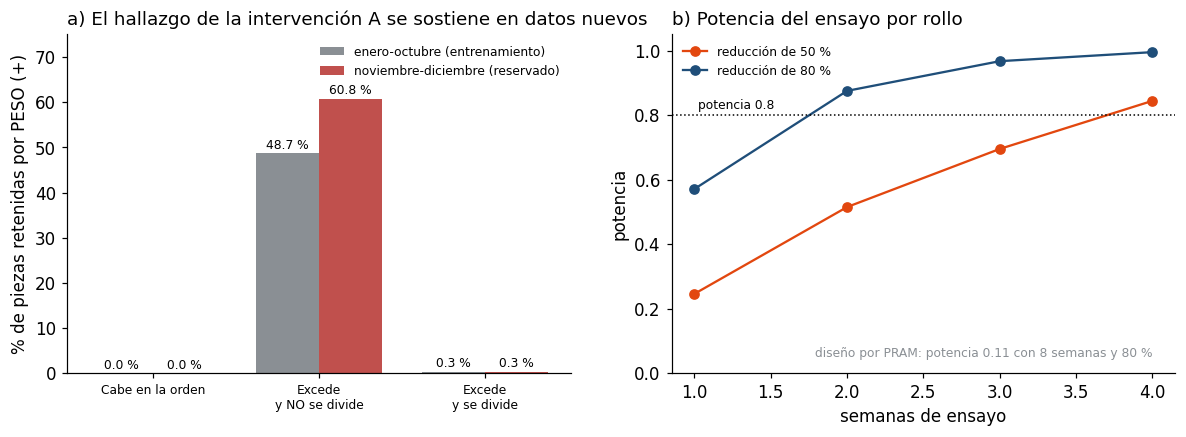

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
t = h1.xs('peso_mas_pct', axis=1, level=1)[['entrenamiento', 'prueba']]
x = np.arange(len(t)); w = .38
ax[0].bar(x - w / 2, t['entrenamiento'], w, color=COLORES['gris'], label='enero-octubre (entrenamiento)')
ax[0].bar(x + w / 2, t['prueba'], w, color=COLORES['rojo'], label='noviembre-diciembre (reservado)')
for i, (a_, b_) in enumerate(zip(t['entrenamiento'], t['prueba'])):
    ax[0].text(i - w / 2, a_ + 1, f'{a_:.1f} %', ha='center', fontsize=8); ax[0].text(i + w / 2, b_ + 1, f'{b_:.1f} %', ha='center', fontsize=8)
ax[0].set_xticks(x); ax[0].set_xticklabels([i.replace(' y ', chr(10) + 'y ') for i in t.index], fontsize=8)
ax[0].set_ylabel('% de piezas retenidas por PESO (+)'); ax[0].legend(fontsize=8); ax[0].set_ylim(0, 75)
ax[0].set_title('a) El hallazgo de la intervención A se sostiene en datos nuevos')
for e, c in [('50 %', COLORES['naranja']), ('80 %', COLORES['azul'])]:
    tt = pot_r[pot_r['reducción supuesta'] == e]
    ax[1].plot(tt.semanas, tt.potencia, 'o-', color=c, label=f'reducción de {e}')
pr_ = pot[pot['semanas de intervención'] == 8]
ax[1].axhline(.8, color='k', ls=':', lw=1); ax[1].text(1.02, .82, 'potencia 0.8', fontsize=8)
ax[1].text(4, .05, f"diseño por PRAM: potencia {pr_[pr_['reducción supuesta'] == '80 %'].potencia.iloc[0]:.2f} con 8 semanas y 80 %", ha='right', fontsize=8, color=COLORES['gris'])
ax[1].set_xlabel('semanas de ensayo'); ax[1].set_ylabel('potencia'); ax[1].set_ylim(0, 1.05); ax[1].legend(fontsize=8)
ax[1].set_title('b) Potencia del ensayo por rollo')
guardar(fig, '08_intervencion_A'); plt.show()

**Cómo leerlo.** Con asignación por rollo, la potencia sube muchísimo, porque cada rollo aporta información y el efecto esperado es enorme (de ~49 % a casi 0 en los rollos tratados).

**Duración propuesta:** **4 semanas** de ensayo. Detectar una reducción del 50 % requiere pocas semanas, pero 4 dan margen para observar los guardrails (PESO −, días de espera) con volumen suficiente y para cubrir variaciones de programa.

**Cuidado con el guardrail de PESO (−).** Detectar con potencia un aumento de PESO (−) de 1 % a 4 % requeriría ~400 rollos por grupo, más de 10 semanas. Por eso el guardrail se vigila con una **regla de paro** con umbral fijo, no con una prueba de hipótesis.

### 5. Experimento técnico: corrección del preset de fuerza al inicio de campaña
**Propuesta:** restar al preset de fuerza la corrección por asentamiento del rodillo en las primeras 20 piezas de cada campaña: ≈ 100 kN en las piezas 1-10 y ≈ 25 kN en las 11-20 (Notebook 07; en noviembre-diciembre el efecto fue aún mayor, −156 kN).

**Primera opción: ensayo aleatorizado por campaña.** Cada campaña se sortea a preset corregido o estándar. El resultado primario es el ΔFuerza medio de sus primeras 20 piezas. Calculamos cuántas campañas harían falta.

In [12]:
A = ENT[ENT.pob_A == 1].copy()
A['dF_dentro'] = A['delta_fuerza'] - A.groupby('prod_ancho')['delta_fuerza'].transform('mean')
ini = A[A.piezas_en_campana <= 20].groupby('campana')['dF_dentro'].mean()
sig = A[A.piezas_en_campana.between(21, 60)].groupby('campana')['dF_dentro'].mean()
par = (ini - sig).dropna()
camp_sem = A.campana.nunique() / A.fecha.dt.to_period('W').nunique()
z = stats.norm.ppf(.975) + stats.norm.ppf(.8)
filas = []
for nombre, sd in [('aleatorizado: ΔFuerza medio piezas 1-20', ini.std()), ('aleatorizado pareado: (1-20) − (21-60) en la misma campaña', par.std())]:
    for delta in (60, 100):
        n = int(np.ceil(2 * (z * sd / delta) ** 2))
        filas.append({'diseño': nombre, 'DE entre campañas (kN)': round(sd), 'efecto (kN)': delta, 'campañas totales': 2 * n,
                      'semanas': round(2 * n / camp_sem, 1)})
pot_D = pd.DataFrame(filas)
pot_D.to_csv(RESULTADOS / '08_potencia_D.csv', index=False)
print(f"Campañas por semana: {camp_sem:.1f}")
pot_D

Campañas por semana: 13.2


,diseño,DE entre campañas (kN),efecto (kN),campañas totales,semanas
0,aleatorizado: ΔFuerza medio piezas 1-20,390,60,1330,100.7
1,aleatorizado: ΔFuerza medio piezas 1-20,390,100,480,36.4
2,aleatorizado pareado: (1-20) − (21-60) en la m...,399,60,1386,105.0
3,aleatorizado pareado: (1-20) − (21-60) en la m...,399,100,500,37.9


**Resultado: un ensayo aleatorizado no es viable.** El ruido pieza a pieza de ΔFuerza es tan grande (DE ~400 kN entre campañas, incluso comparando dentro de la misma campaña) que detectar 100 kN pediría cientos de campañas, más de medio año.

**Segunda opción: cambio de setup monitoreado.** Como la corrección es de **bajo riesgo** (solo ajusta el preset hacia lo que la línea ya aplica), se puede implementar en todas las campañas y evaluar contra la línea base histórica (las campañas de 2025), con un análisis de **series de tiempo interrumpidas**: ¿cambia la diferencia entre el ΔFuerza de las piezas 1-20 y el de las piezas 21-60 después del cambio?

In [13]:
n_hist = len(par); sd = par.std()
filas = []
for delta in (60, 100):
    se_obj = delta / z                                     # error estándar necesario para potencia 0.8
    inv = (se_obj / sd) ** 2 - 1 / n_hist
    n_post = int(np.ceil(1 / inv)) if inv > 0 else np.inf
    filas.append({'efecto (kN)': delta, 'campañas históricas (línea base)': n_hist, 'campañas después del cambio': n_post,
                  'semanas de monitoreo': round(n_post / camp_sem, 1) if np.isfinite(n_post) else 'inviable'})
pot_D2 = pd.DataFrame(filas)
pot_D2.to_csv(RESULTADOS / '08_potencia_D_monitoreo.csv', index=False)
pot_D2

,efecto (kN),campañas históricas (línea base),campañas después del cambio,semanas de monitoreo
0,60,541,963,72.9
1,100,541,163,12.3


| Elemento | Definición |
|---|---|
| **Hipótesis** | Corregir el preset de fuerza en las piezas 1-20 de cada campaña acerca ΔFuerza a 0 en esas piezas, sin afectar la elongación ni los defectos |
| **Diseño** | Cambio de setup en todas las campañas; series de tiempo interrumpidas contra las campañas de 2025 (diferencia entre piezas 1-20 y 21-60 de la misma campaña, antes y después) |
| **Resultado primario** | Diferencia de ΔFuerza (piezas 1-20 menos piezas 21-60) por campaña |
| **Guardrails** | Desviación de la elongación frente a su objetivo en las piezas 1-20; defectos B2 en las piezas 1-20 |
| **Regla de paro** | Si la elongación de las piezas 1-20 sale de tolerancia en más de 2 puntos porcentuales por encima de su línea base durante una semana |
| **Duración** | La que indique la tabla para un efecto de 100 kN |
| **Limitación** | Sin grupo de control simultáneo, cualquier cambio del proceso en esas semanas se confundiría con el efecto. Se mitiga revisando las piezas 21-60, que no reciben la corrección y deben quedar igual |

### 6. Datos del Skinpass que faltan para responder mejor

| Dato | Para qué serviría | Estado en 2025 |
|---|---|---|
| Planeza medida de salida (I-units) por pieza | Medir el objetivo real del bending; hoy solo vemos defectos de forma | No existe (columnas vacías) |
| Velocidad de la línea | Confusor del esfuerzo y de la elongación | No existe |
| Criterio de elección del modo Fuerza (RCO) | Separar el efecto del modo de la selección (forma ×7.9) | No existe |
| Correcciones del operador sobre el preset | Separar operador, turno y receta (brecha de 140 kN) | No existe |
| Lógica y límites del control de bending | Entender por qué el bending real se satura | No existe |
| Rugosidad del rodillo al montar y al retirar | Medir el desgaste en lugar de aproximarlo por posición | No existe |
| Motivo de no dividir un rollo que excede la orden | Afinar la regla de la intervención A | No existe |

## E. Interpretación de los resultados

**1. La evaluación en el periodo reservado confirma cuatro de los cinco hallazgos.**
- **H1 (peso) se sostiene con más fuerza:** en noviembre-diciembre, el 60.8 % de las piezas de rollos que exceden la orden y no se dividen se retuvo por PESO (+), contra 0.10 % del resto (620 veces más). Sin los programas que cruzan la frontera: 50.5 %.
- **H2 se sostiene:** agregar el MC4 a los controles no mejora la predicción de ΔBending en datos nuevos (−1.2 puntos).
- **H3 se refuta:** el bloque Skinpass, con el operador, **empeora** la predicción de ΔBending en noviembre-diciembre (−6.1 puntos). La ventaja del operador que vimos en el Notebook 04 no se transfiere a un periodo nuevo, probablemente porque cambian los operadores o sus turnos. **La intervención E pierde su principal argumento.** En general, nada predice ΔBending en el periodo nuevo mejor que la media del producto: su variación sigue sin explicarse.
- **H4 (asentamiento) se sostiene y crece:** −156 kN en las primeras 10 piezas (IC −224 a −88), contra −98 kN en entrenamiento.
- **H5 (días de espera) se sostiene y crece:** +66 kN por desviación estándar de espera (IC 51 a 82), contra +52 kN. En prueba, el MC4 (donde están los días) mejora la predicción de ΔFuerza en 6 puntos.

**2. La tabla de decisión elige A.** Es la única intervención con impacto alto, evidencia confirmada en datos nuevos, riesgo bajo y que se puede probar rápido. D queda segunda: evidencia sólida y riesgo bajo, pero no promete reducir defectos.

**3. El diseño por PRAM se descarta; el diseño por rollo funciona.** Los eventos están concentrados: un solo PRAM tiene el 31 % y tres tienen la mitad. Con el PRAM como unidad, la potencia no pasa de ~0.1. Sorteando cada rollo que excede la orden, dentro de bloques PRAM × semana, **4 semanas dan potencia 0.84** para una reducción del 50 % y ~1.0 para una del 80 %.

**4. El experimento técnico (D) no admite un ensayo aleatorizado.** El ruido de ΔFuerza es tan grande que detectar 100 kN requeriría ~500 campañas (~37 semanas). Se propone como **cambio de setup monitoreado**: ~163 campañas (~12 semanas) contra la línea base histórica.

## F. Conclusiones de la etapa

### Qué proponemos probar en planta
1. **Experimento principal (intervención A):** ensayo aleatorizado por rollo, bloqueado por PRAM × semana, de **4 semanas**. Validar en la planeación que cada rollo cabe en el peso de su orden (dividir o reasignar). Guardrails: retención por PESO (−) y días de espera, con regla de paro.
2. **Cambio monitoreado (variante de D):** corregir el preset de fuerza en las primeras 20 piezas de cada campaña (~100 kN y ~25 kN), con **12 semanas** de monitoreo contra 2025.
3. **No se proponen todavía:** B (feedforward del MC4), C (ancho en MC4) y E (operadores). La evidencia histórica no las sostiene, y E fue refutada en el periodo reservado.
4. **En espera:** F (duración de campaña), hasta descartar que la subida de forma sea selección del material programado al final.

### Hallazgos de la evaluación final
| Hallazgo | Veredicto en noviembre-diciembre |
|---|---|
| H1 · Peso (intervención A) | Se sostiene (60.8 % vs 0.10 %) |
| H2 · El MC4 no mejora ΔBending | Se sostiene (−1.2 pts) |
| H3 · El Skinpass (operador) mejora ΔBending | **Se refuta** (−6.1 pts) |
| H4 · Asentamiento del rodillo | Se sostiene (−156 kN) |
| H5 · Días de espera → ΔFuerza | Se sostiene (+66 kN por DE) |

### Limitaciones
- La tasa de H1 en el periodo reservado se consultó al preparar el protocolo; las demás comprobaciones se corrieron aquí por primera vez.
- La simulación de potencia supone que la regla evita el evento con la probabilidad indicada y que los rollos tratados se pueden dividir o reasignar.
- El cambio monitoreado (D) no tiene control simultáneo.

### Datos que pedimos a Ternium
Planeza medida de salida, velocidad de la línea, criterio de elección del modo Fuerza, correcciones del operador sobre el preset, lógica del control de bending, rugosidad de los rodillos y motivo de no dividir un rollo que excede la orden (sección 6).